# Agglomerative Hierarchical Clustering — World Happiness Report
**23CSE301 Machine Learning · Capstone (Clustering track, Review 2)**

Bottom-up clustering of countries. We draw dendrograms, compare **ward / complete / average / single** linkage, and compare cluster quality with silhouette (plus Davies-Bouldin and Calinski-Harabasz). No labels are used for fitting.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, warnings
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12})
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet
from scipy.spatial.distance import pdist
from sklearn.cluster import AgglomerativeClustering

## 1. Dataset loading & inspection

In [2]:
raw = pd.read_csv("../data/world_happiness_report.csv")
print("Shape:", raw.shape)
print("Countries:", raw["Country Name"].nunique(), "| Years:", raw["Year"].min(), "-", raw["Year"].max())
print("Duplicate rows:", raw.duplicated().sum())
display(raw.dtypes.astype(str).to_frame("dtype").join(raw.isna().sum().rename("missing")))
raw.head()

Shape: (2199, 13)
Countries: 165 | Years: 2005 - 2022
Duplicate rows: 0


,dtype,missing
Country Name,str,0
Regional Indicator,str,112
Year,int64,0
Life Ladder,float64,0
Log GDP Per Capita,float64,20
Social Support,float64,13
Healthy Life Expectancy At Birth,float64,54
Freedom To Make Life Choices,float64,33
Generosity,float64,73
Perceptions Of Corruption,float64,116


,Country Name,Regional Indicator,Year,Life Ladder,Log GDP Per Capita,Social Support,Healthy Life Expectancy At Birth,Freedom To Make Life Choices,Generosity,Perceptions Of Corruption,Positive Affect,Negative Affect,Confidence In National Government
0,Afghanistan,South Asia,2008,3.723590,7.350416,0.450662,50.500000,0.718114,0.167652,0.881686,0.414297,0.258195,0.612072
1,Afghanistan,South Asia,2009,4.401778,7.508646,0.552308,50.799999,0.678896,0.190809,0.850035,0.481421,0.237092,0.611545
2,Afghanistan,South Asia,2010,4.758381,7.613900,0.539075,51.099998,0.600127,0.121316,0.706766,0.516907,0.275324,0.299357
3,Afghanistan,South Asia,2011,3.831719,7.581259,0.521104,51.400002,0.495901,0.163571,0.731109,0.479835,0.267175,0.307386
4,Afghanistan,South Asia,2012,3.782938,7.660506,0.520637,51.700001,0.530935,0.237588,0.775620,0.613513,0.267919,0.435440


## 2. Preprocessing (same pipeline as the K-Means notebook)

Country-level table: (165, 10)
Missing cells before imputation: 31
IQR outlier counts per feature:
Life Ladder                           0
Log GDP Per Capita                    0
Social Support                        5
Healthy Life Expectancy At Birth      2
Freedom To Make Life Choices          1
Generosity                            4
Perceptions Of Corruption            18
Positive Affect                       0
Negative Affect                       4
Confidence In National Government     2
Dropped for redundancy (|r|>0.90): none


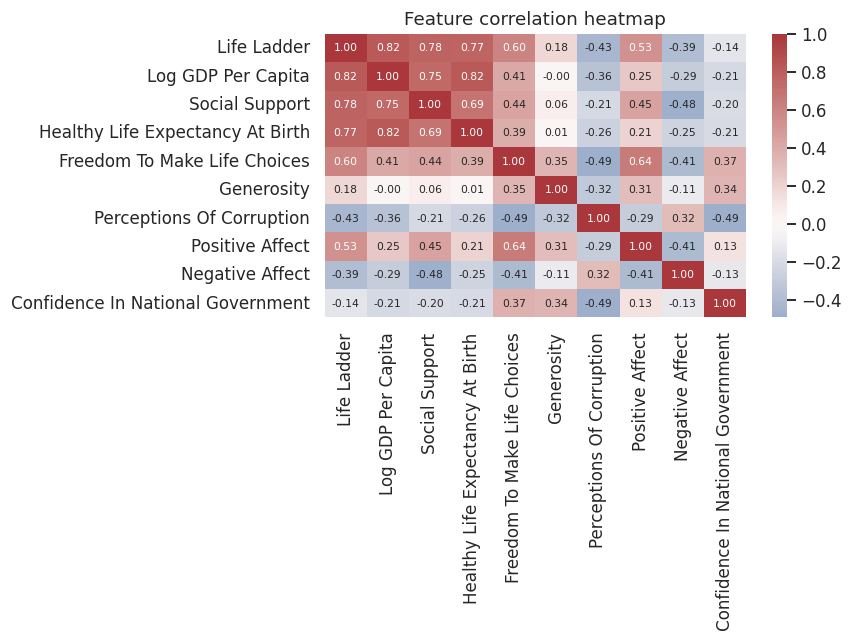

Model input: (165, 10) | mean~0: True | std~1: True


In [3]:
# --- Cleaning ---------------------------------------------------------------
# Regional Indicator is missing for some rows: recover it from the same country's other years.
# It is used ONLY for post-hoc validation, never as a clustering input.
region = raw.groupby("Country Name")["Regional Indicator"].agg(lambda s: s.mode().iloc[0] if s.notna().any() else "Unknown")
FEATURES = [c for c in raw.columns if c not in ["Country Name", "Regional Indicator", "Year"]]
# Aggregate the panel to one row per country (mean over available years; NaNs are skipped).
df = raw.groupby("Country Name")[FEATURES].mean()
print("Country-level table:", df.shape)
print("Missing cells before imputation:", int(df.isna().sum().sum()))
df = df.fillna(df.median())          # median imputation: robust to skew/outliers
true_region = region.loc[df.index]   # kept aside for validation only
# --- Outliers (IQR rule): reported, kept (they are real countries, not errors) ---
q1, q3 = df.quantile(.25), df.quantile(.75); iqr = q3 - q1
print("IQR outlier counts per feature:"); print(((df < q1 - 1.5*iqr) | (df > q3 + 1.5*iqr)).sum().to_string())
# --- Feature selection: drop one of any pair with |r| > 0.90 ----------------
corr = df.corr(); upper = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool))
drop = [c for c in upper.columns if (upper[c].abs() > 0.90).any()]
print("Dropped for redundancy (|r|>0.90):", drop or "none")
plt.figure(figsize=(8, 6)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, annot_kws={"size": 7})
plt.title("Feature correlation heatmap"); plt.tight_layout(); plt.show()
df = df.drop(columns=drop); FEATURES = list(df.columns)
# --- Encoding: all selected features are numeric, so no encoding is needed ---
assert all(pd.api.types.is_numeric_dtype(t) for t in df.dtypes)
# --- Scaling: distance-based methods need comparable scales ------------------
# (Unsupervised task -> no train/test split; the scaler is fitted on the full country table.)
X = StandardScaler().fit_transform(df)
print("Model input:", X.shape, "| mean~0:", np.allclose(X.mean(0), 0), "| std~1:", np.allclose(X.std(0), 1))

## 3. Linkage strategies explained
Agglomerative clustering starts with every country as its own cluster and repeatedly merges the two *closest* clusters. "Closest" depends on the linkage:

| Linkage | Distance between clusters | Typical behaviour |
|---|---|---|
| **ward** | merge that least increases total within-cluster variance (Euclidean only) | compact, similar-sized clusters; closest to K-Means |
| **complete** | *maximum* pairwise distance | compact clusters, sensitive to outliers |
| **average** | *mean* pairwise distance (UPGMA) | compromise between complete and single |
| **single** | *minimum* pairwise distance | finds elongated shapes but suffers **chaining** (often one huge cluster plus tiny ones) |

## 4. Dendrograms for all four linkages
A horizontal cut at a given height yields that many clusters; long vertical gaps suggest a natural number of clusters. Plots are truncated to the last 25 merges for readability.

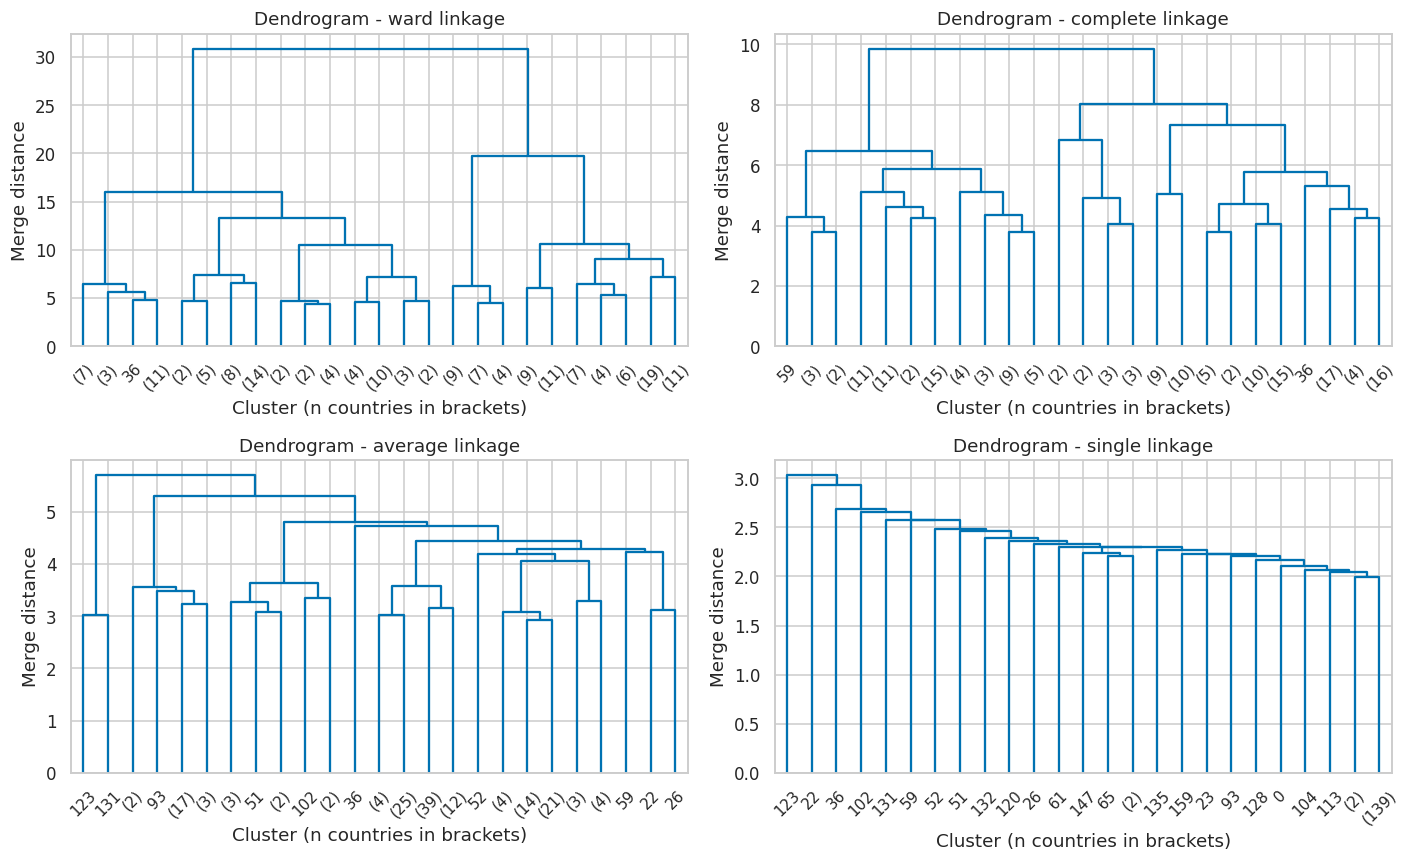

Cophenetic correlation (how faithfully the tree preserves pairwise distances; higher is better):


,cophenetic_corr
ward,0.557
complete,0.584
average,0.680
single,0.478


In [4]:
METHODS = ["ward", "complete", "average", "single"]
Z = {m: linkage(X, method=m) for m in METHODS}
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for a, m in zip(axes.ravel(), METHODS):
    dendrogram(Z[m], truncate_mode="lastp", p=25, ax=a, color_threshold=0, above_threshold_color="#0072B2")
    a.set(title=f"Dendrogram - {m} linkage", xlabel="Cluster (n countries in brackets)", ylabel="Merge distance")
plt.tight_layout(); plt.show()
coph = pd.Series({m: cophenet(Z[m], pdist(X))[0] for m in METHODS}, name="cophenetic_corr")
print("Cophenetic correlation (how faithfully the tree preserves pairwise distances; higher is better):"); display(coph.round(3).to_frame())

## 5. Silhouette vs number of clusters, per linkage

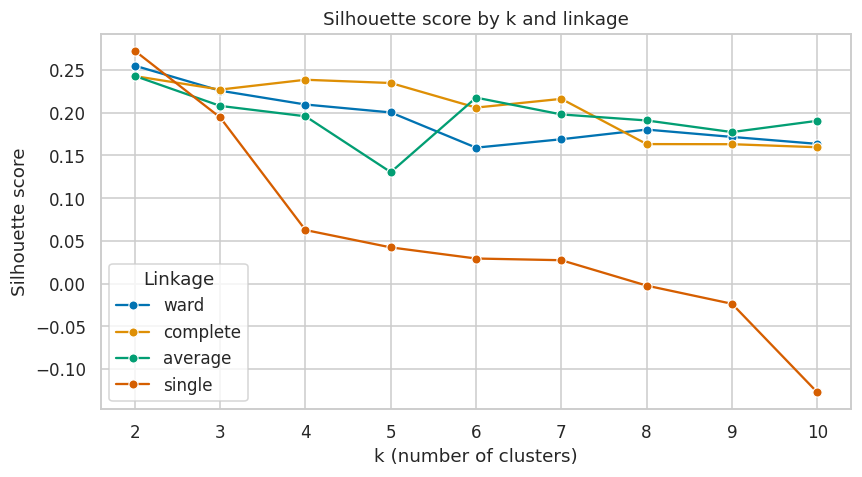

linkage,average,complete,single,ward
k,,,,
2,0.243,0.243,0.272,0.255
3,0.208,0.227,0.194,0.226
4,0.196,0.238,0.063,0.210
5,0.130,0.235,0.042,0.200
6,0.218,0.206,0.029,0.159
7,0.198,0.216,0.027,0.169
8,0.191,0.163,-0.002,0.180
9,0.177,0.163,-0.024,0.172
10,0.190,0.160,-0.127,0.163


In [5]:
def quality(X, labels):
    return dict(silhouette=silhouette_score(X, labels), davies_bouldin=davies_bouldin_score(X, labels),
                calinski_harabasz=calinski_harabasz_score(X, labels))

rows = []
for m in METHODS:
    for k in range(2, 11):
        lab = AgglomerativeClustering(n_clusters=k, linkage=m).fit_predict(X)
        rows.append(dict(linkage=m, k=k, min_cluster=int(np.bincount(lab).min()), **quality(X, lab)))
sw = pd.DataFrame(rows)
plt.figure(figsize=(8, 4.5)); sns.lineplot(data=sw, x="k", y="silhouette", hue="linkage", marker="o")
plt.title("Silhouette score by k and linkage"); plt.xlabel("k (number of clusters)"); plt.ylabel("Silhouette score"); plt.legend(title="Linkage"); plt.tight_layout(); plt.show()
display(sw.pivot(index="k", columns="linkage", values="silhouette").round(3))

**Caution on single linkage:** a high silhouette can arise from isolating one or two outlying countries in tiny clusters. The `min_cluster` column in `sw` shows this, so when selecting a model we require every cluster to hold at least 5% of the countries.

In [6]:
K_FINAL = int(sw[sw.linkage == "ward"].set_index("k")["silhouette"].idxmax())   # k chosen on ward, then all linkages compared at the same k
print("Shared k used to compare all linkages:", K_FINAL)
labels, rows = {}, []
for m in METHODS:
    labels[m] = AgglomerativeClustering(n_clusters=K_FINAL, linkage=m).fit_predict(X)
    cnt = np.bincount(labels[m])
    rows.append(dict(linkage=m, sizes=cnt.tolist(), min_share=cnt.min() / len(X), **quality(X, labels[m])))
cmp_ = pd.DataFrame(rows).set_index("linkage")
cmp_["valid (>=5% each)"] = cmp_["min_share"] >= 0.05
display(cmp_.round(3))
best = cmp_[cmp_["valid (>=5% each)"]]["silhouette"].idxmax(); print("Best valid linkage by silhouette:", best)

Shared k used to compare all linkages: 2


,sizes,min_share,silhouette,davies_bouldin,calinski_harabasz,valid (>=5% each)
linkage,,,,,,
ward,"[87, 78]",0.473,0.255,1.497,66.188,True
complete,"[99, 66]",0.400,0.243,1.506,61.580,True
average,"[163, 2]",0.012,0.243,0.977,4.296,False
single,"[164, 1]",0.006,0.272,0.580,2.702,False


Best valid linkage by silhouette: ward


## 6. Cluster visualisation (PCA for all linkages; t-SNE for the best)

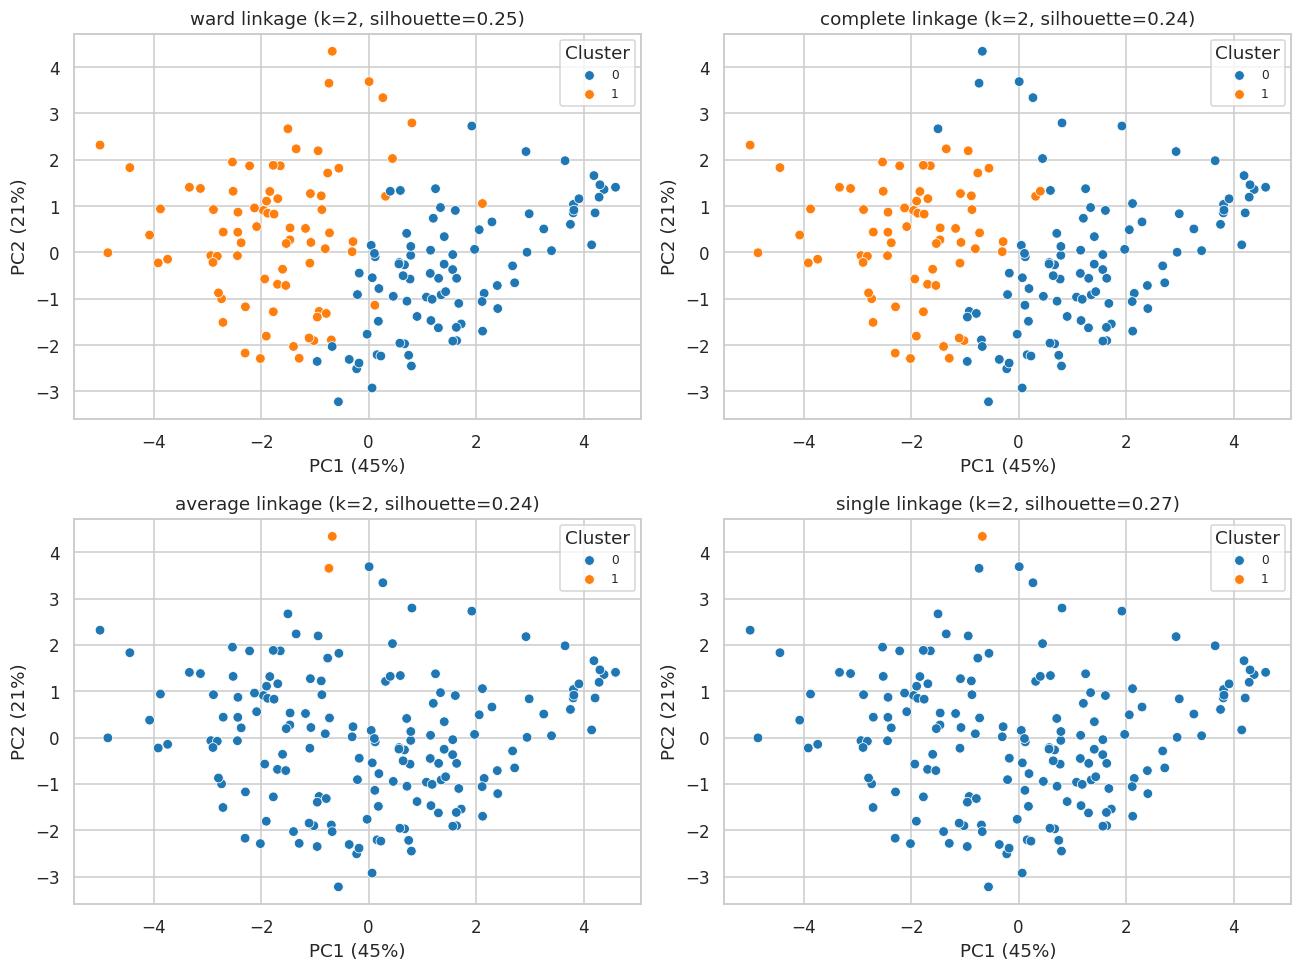

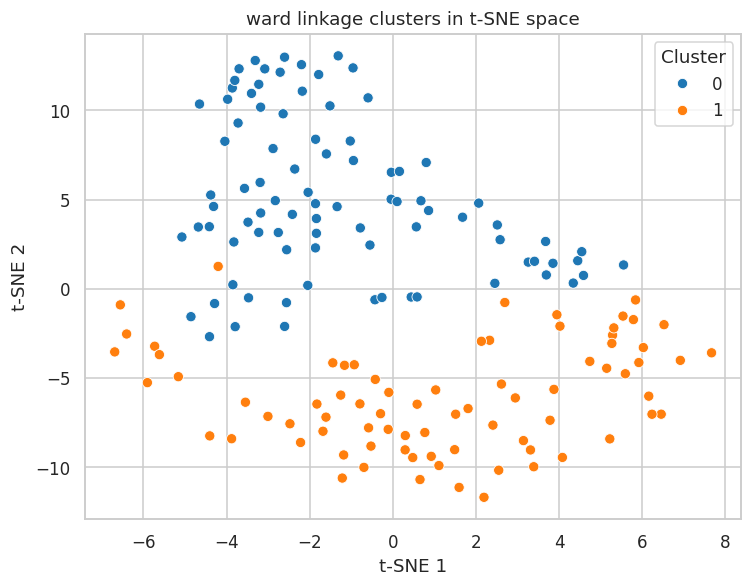

In [7]:
pca = PCA(n_components=2, random_state=RANDOM_STATE); P = pca.fit_transform(X)
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for a, m in zip(axes.ravel(), METHODS):
    sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=labels[m], palette="tab10", s=40, ax=a, legend="full")
    a.set(title=f"{m} linkage (k={K_FINAL}, silhouette={cmp_.loc[m, 'silhouette']:.2f})", xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%})", ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
    a.legend(title="Cluster", fontsize=8)
plt.tight_layout(); plt.show()
T = TSNE(n_components=2, perplexity=30, init="pca", random_state=RANDOM_STATE).fit_transform(X)
plt.figure(figsize=(7, 5.5)); sns.scatterplot(x=T[:, 0], y=T[:, 1], hue=labels[best], palette="tab10", s=45)
plt.title(f"{best} linkage clusters in t-SNE space"); plt.xlabel("t-SNE 1"); plt.ylabel("t-SNE 2"); plt.legend(title="Cluster"); plt.tight_layout(); plt.show()

## 7. Profile of the best model and post-hoc validation

,n_countries,Life Ladder,Log GDP Per Capita,Social Support,Healthy Life Expectancy At Birth,Freedom To Make Life Choices,Generosity,Perceptions Of Corruption,Positive Affect,Negative Affect,Confidence In National Government
cluster,,,,,,,,,,,
0,87,6.18,10.11,0.88,67.07,0.80,0.0,0.70,0.69,0.25,0.46
1,78,4.53,8.43,0.71,57.48,0.67,0.0,0.78,0.60,0.31,0.56


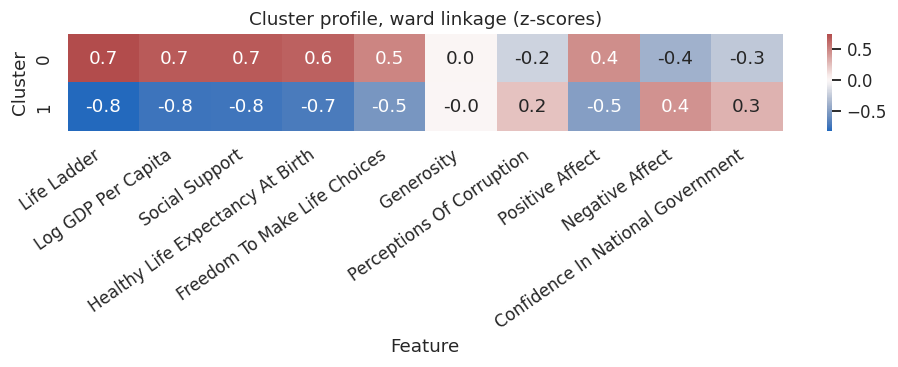

Adjusted Rand Index vs Regional Indicator (validation only): 0.173


In [8]:
res = df.copy(); res["cluster"] = labels[best]
prof = res.groupby("cluster").mean().round(2); prof.insert(0, "n_countries", res["cluster"].value_counts().sort_index()); display(prof)
z = pd.DataFrame(StandardScaler().fit_transform(df), index=df.index, columns=df.columns).groupby(labels[best]).mean()
plt.figure(figsize=(9, 3.5)); sns.heatmap(z, annot=True, fmt=".1f", cmap="vlag", center=0)
plt.title(f"Cluster profile, {best} linkage (z-scores)"); plt.xlabel("Feature"); plt.ylabel("Cluster"); plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()
mask = (true_region != "Unknown").to_numpy()
print("Adjusted Rand Index vs Regional Indicator (validation only):", round(adjusted_rand_score(true_region[mask], labels[best][mask]), 3))

## 8. Conclusion

In [9]:
print(f"""Summary (all numbers computed above):
- {X.shape[0]} countries x {X.shape[1]} standardised indicators.
- Shared k={K_FINAL} (silhouette-optimal for ward). Silhouette by linkage: {cmp_['silhouette'].round(3).to_dict()}.
- Best linkage among those without degenerate tiny clusters: {best}.
- Cophenetic correlation by linkage: {coph.round(3).to_dict()}.""")

Summary (all numbers computed above):
- 165 countries x 10 standardised indicators.
- Shared k=2 (silhouette-optimal for ward). Silhouette by linkage: {'ward': 0.255, 'complete': 0.243, 'average': 0.243, 'single': 0.272}.
- Best linkage among those without degenerate tiny clusters: ward.
- Cophenetic correlation by linkage: {'ward': 0.557, 'complete': 0.584, 'average': 0.68, 'single': 0.478}.


**Interpretation notes.** Ward tends to give balanced clusters comparable to K-Means; single linkage typically chains. Use the table in §5 (not just the headline silhouette) to judge whether a linkage produced a degenerate partition. Unlike K-Means, hierarchical clustering gives a full tree, so any k can be explored without refitting, at O(n²) memory cost, which is fine for ~160 countries but costly for very large data.

**Limitations:** Euclidean distance only (required by ward); no way to assign *new* countries without refitting; same imputation/averaging simplifications as the K-Means notebook.